<a href="https://colab.research.google.com/github/anupbagale/Image_Processing/blob/main/notebooks/02_zooming.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Zooming

Zooming an image by a factor $k$ means making a new image that is $k$ times larger and deciding
what value each new pixel should get. Each new pixel is mapped back to a position in the original
image, and that position usually falls between original pixels. The two methods here differ in
how they deal with that.

- **Replication** (nearest neighbour) copies the value of the closest original pixel. Every pixel
  turns into a $k \times k$ block.
- **Bilinear interpolation** takes a weighted average of the four surrounding pixels, so the
  result is smoother.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

plt.rcParams["image.cmap"] = "gray"

We zoom into a small 32 x 32 crop around the eye and the camera, so the difference is easy to see.

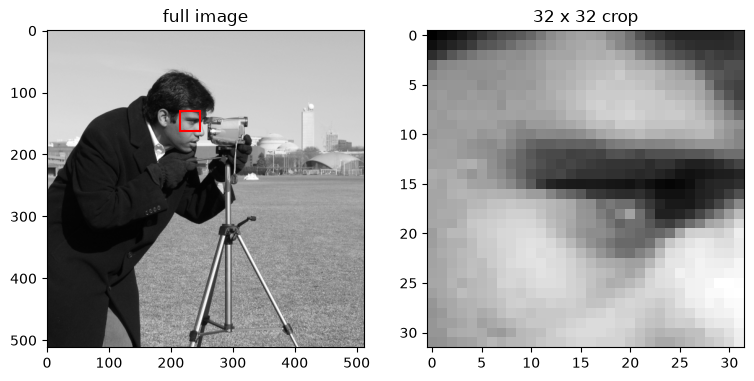

In [2]:
image = data.camera()
crop = image[130:162, 215:247]
zoom = 8

fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
ax[0].imshow(image); ax[0].set_title("full image")
ax[0].add_patch(plt.Rectangle((215, 130), 32, 32, fill=False, edgecolor="red", lw=1.5))
ax[1].imshow(crop); ax[1].set_title("32 x 32 crop")
plt.show()

## Replication

Pixel $(i, j)$ of the zoomed image takes its value from pixel $(\lfloor i/k \rfloor, \lfloor j/k \rfloor)$
of the original.

In [3]:
def zoom_replication(img, k):
    h, w = img.shape[:2]
    out = np.zeros((h * k, w * k) + img.shape[2:], dtype=img.dtype)
    for i in range(h * k):
        for j in range(w * k):
            out[i, j] = img[int(i / k), int(j / k)]
    return out


replicated = zoom_replication(crop, zoom)
print("crop:", crop.shape, " zoomed:", replicated.shape)

crop: (32, 32)  zoomed: (256, 256)


## Bilinear interpolation

For a new pixel we first find where it lands in the original image. Treating pixels as small
squares with their centre at the integer position, the zoomed pixel $i$ maps to

$$y = \frac{i + 0.5}{k} - 0.5$$

(and the same for $x$). Let $y_0 = \lfloor y \rfloor$, $x_0 = \lfloor x \rfloor$,
$d_y = y - y_0$ and $d_x = x - x_0$. The value is a weighted average of the four neighbours:

$$
f = (1-d_y)\big[(1-d_x) f_{00} + d_x f_{01}\big] + d_y\big[(1-d_x) f_{10} + d_x f_{11}\big]
$$

Positions outside the image are clamped to the border.

In [4]:
def zoom_bilinear(img, k):
    h, w = img.shape
    new_h, new_w = int(h * k), int(w * k)

    y = np.clip((np.arange(new_h) + 0.5) / k - 0.5, 0, h - 1)
    x = np.clip((np.arange(new_w) + 0.5) / k - 0.5, 0, w - 1)
    y0 = np.floor(y).astype(int)
    x0 = np.floor(x).astype(int)
    y1 = np.minimum(y0 + 1, h - 1)
    x1 = np.minimum(x0 + 1, w - 1)
    dy = (y - y0)[:, None]
    dx = (x - x0)[None, :]

    f = img.astype(float)
    top = f[y0][:, x0] * (1 - dx) + f[y0][:, x1] * dx
    bottom = f[y1][:, x0] * (1 - dx) + f[y1][:, x1] * dx
    return np.round(top * (1 - dy) + bottom * dy).astype(np.uint8)


bilinear = zoom_bilinear(crop, zoom)

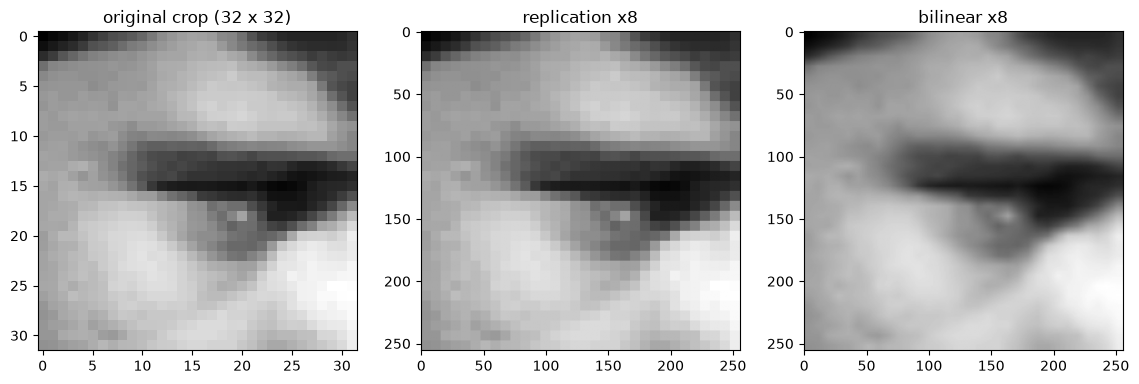

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 5))
ax[0].imshow(crop); ax[0].set_title("original crop (32 x 32)")
ax[1].imshow(replicated); ax[1].set_title(f"replication x{zoom}")
ax[2].imshow(bilinear); ax[2].set_title(f"bilinear x{zoom}")
plt.show()

Replication keeps edges sharp but the blocks are clearly visible. Bilinear interpolation removes
the blocks but makes the image look slightly blurred.

## Comparison with OpenCV

`cv2.resize` with `INTER_NEAREST` and `INTER_LINEAR` does the same two things. OpenCV computes the
bilinear weights with fixed-point integers, so a few pixels can differ by one grey level.

In [6]:
cv_nearest = cv2.resize(crop, None, fx=zoom, fy=zoom, interpolation=cv2.INTER_NEAREST)
cv_linear = cv2.resize(crop, None, fx=zoom, fy=zoom, interpolation=cv2.INTER_LINEAR)

print("replication same as INTER_NEAREST:", np.array_equal(replicated, cv_nearest))
diff = np.abs(bilinear.astype(int) - cv_linear.astype(int))
print(f"bilinear vs INTER_LINEAR: largest difference {diff.max()} grey level, "
      f"{(diff == 0).mean():.1%} of pixels identical")

replication same as INTER_NEAREST: True
bilinear vs INTER_LINEAR: largest difference 1 grey level, 88.4% of pixels identical
